# Visualizing events with `neuralset.events.viz`

`neuralset` ships three plotting functions in `neuralset/events/viz.py`. Each answers a question at a different altitude:

| function | scope | question it answers |
| --- | --- | --- |
| `plot_events` | one timeline | what happened inside this recording, and when |
| `plot_study` | one or more studies | how is recorded time distributed over subjects and timelines |
| `plot_overlap` | one or more studies | which stimuli are shared between subjects, sessions or studies |

All three read the standardized events dataframe and return a `plotly.graph_objects.Figure`, so the same call works in a notebook, in a script, or behind a web API.

This notebook runs them against four of our studies, each picked for what it exercises:

- **singer_2025** for `plot_events`, because one of its blocks carries ten different event types at once: neural features, four behavioral streams, trial markers, and spoken words.
- **kunz_2025** for `plot_study` and `plot_overlap`, because it is the only study with more than one subject (T12, T15, T16, T17).
- **willet_2023** and **willet_2021** alongside kunz_2025, to show what the same functions say about several studies pooled together.

It also records where these functions need help with our data. Most of it traces to one root cause: `timeline` and `filepath` are machine identifiers in this project, and `viz.py` treats them as display labels.

Everything here reads the events dataframe only. No stream is ever read, so all of it is metadata-speed. The data drive does have to be mounted, because building a `Study` opens the source files to measure durations.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import plotly.io as pio
from neuralset.events import viz

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.kunz_2025.study import Kunz2025InnerSpeech
from neuralshed.datasets.singer_2025.study import Singer2025CursorControl
from neuralshed.datasets.willet_2021.study import Willett2021Handwriting
from neuralshed.datasets.willet_2023.study import Willett2023Sentences

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.width", 200)


def build(cls, folder, query=None):
    """Run a Study over its source folder and return its events."""
    return cls(path=str(dataset_dir(folder) / "data"), query=query).run()


def readable(events, label):
    """Relabel timelines and drop filepath labels, for plotting only."""
    out = events.copy()
    out["timeline"] = label
    if "filepath" in out.columns:
        out["filepath"] = ""
    return out


def ordered(fig, lanes):
    """Set the lane order of a plot_events figure, top to bottom.

    Types missing from `lanes` keep alphabetical order below the named ones.
    """
    present = {trace.y[0] for trace in fig.data if trace.y is not None}
    named = [etype for etype in lanes if etype in present]
    return fig.update_yaxes(
        categoryorder="array",
        categoryarray=list(reversed(named + sorted(present.difference(named)))),
    )

---
## 1. `plot_events`: one timeline

`plot_events` takes the events of a **single** timeline and draws one horizontal lane per event type. Spans are bars, zero-duration events are tick marks, and text events are labeled with their `text`.

The block below is 180 s of T15 doing the simultaneous speech and cursor task from singer_2025. It is a good stress test because it emits ten types at once: two neural streams, four behavioral streams, the three trial markers, and the word spoken on each trial.

In [2]:
singer = build(
    Singer2025CursorControl,
    "singer_2025",
    query="session == 't15_day00202' and run == 'block02'",
)

print(f"{len(singer)} events over {singer.stop.max():.0f} s")
print(singer.type.value_counts().to_string())

142 events over 180 s
type
Stimulus                41
Action                  41
Intertrial              27
Word                    27
SpikeCounts              1
BandPower                1
CursorPositionSeries     1
TargetPositionSeries     1
DecodedCursorVelocitySeries     1
CursorAssistSeries       1


The distinction the plot draws is already visible in the rows: the six data streams are one event each, spanning the whole block, while the trial markers repeat.

In [3]:
columns = ["type", "start", "duration", "code", "text", "trial_id"]
singer[columns].head(12)

,type,start,duration,code,text,trial_id
0,SpikeCounts,0.00,180.01,NaN,NaN,NaN
1,BandPower,0.00,180.01,NaN,NaN,NaN
2,CursorPositionSeries,0.00,180.01,NaN,NaN,NaN
3,TargetPositionSeries,0.00,180.01,NaN,NaN,NaN
4,DecodedCursorVelocitySeries,0.00,180.01,NaN,NaN,NaN
5,CursorAssistSeries,0.00,180.01,NaN,NaN,NaN
6,Intertrial,0.32,1.00,NaN,NaN,0.0
7,Stimulus,1.32,5.76,3.0,NaN,0.0
8,Word,1.32,1.48,NaN,choice,0.0
9,Action,2.80,4.28,3.0,NaN,0.0


Zoomed into the first 30 s the task structure reads directly off the plot. Each trial is `Intertrial` for a fixed second, then a `Stimulus` presenting the target, the `Word` T15 speaks out loud, and the `Action` covering the cursor movement. The four continuous streams run underneath without a break.

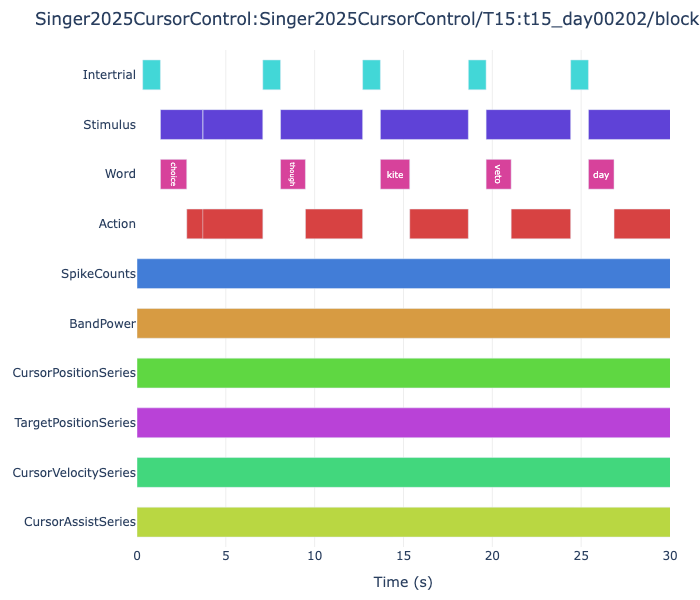

In [4]:
LANES = [
    "Intertrial",
    "Stimulus",
    "Word",
    "Action",
    "SpikeCounts",
    "BandPower",
    "CursorPositionSeries",
    "TargetPositionSeries",
    "DecodedCursorVelocitySeries",
    "CursorAssistSeries",
]

block = readable(singer, singer.session + "/" + singer.run)
fig = ordered(viz.plot_events(block), LANES)
fig.update_xaxes(range=[0, 30])
fig

---
## 2. `plot_study`: where the recorded time is

`plot_study` is a treemap nested **study > subject > timeline**, with rectangle area proportional to timeline duration. It is the answer to "what actually dominates this pile", which a table of session counts cannot give, because sessions are not the same length.

kunz_2025 is the natural first test: four subjects, 41 timelines, and a very uneven split between them.

In [5]:
kunz = build(Kunz2025InnerSpeech, "kunz_2025")

print(f"{len(kunz)} events, {kunz.timeline.nunique()} timelines")
print(kunz.groupby("subject").timeline.nunique().to_string())

12528 events, 41 timelines
subject
Kunz2025InnerSpeech/T12    16
Kunz2025InnerSpeech/T15    10
Kunz2025InnerSpeech/T16    13
Kunz2025InnerSpeech/T17     2


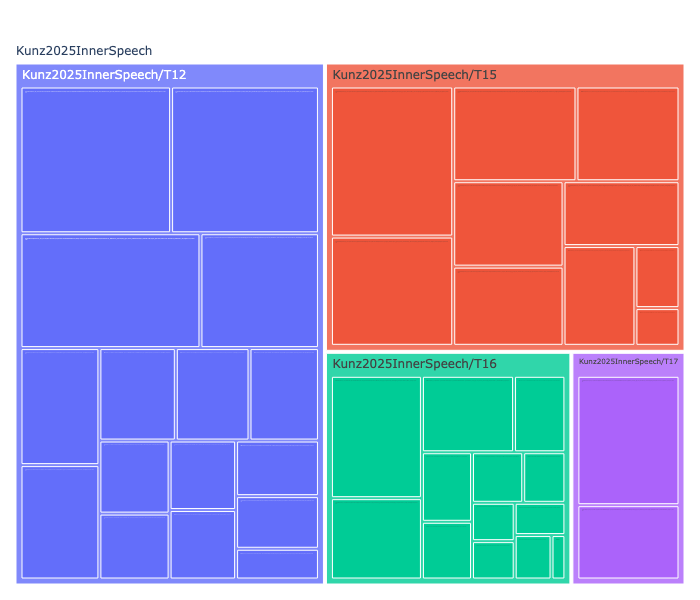

In [6]:
viz.plot_study(kunz)

The subject boxes are right, and the leaves are silently unlabeled. Same root cause as the title above: a 400-character leaf label does not fit in its rectangle, so plotly drops it, and the duration annotation goes with it.

`readable` fixes it. Sessions are the useful leaf here, so that is the label.

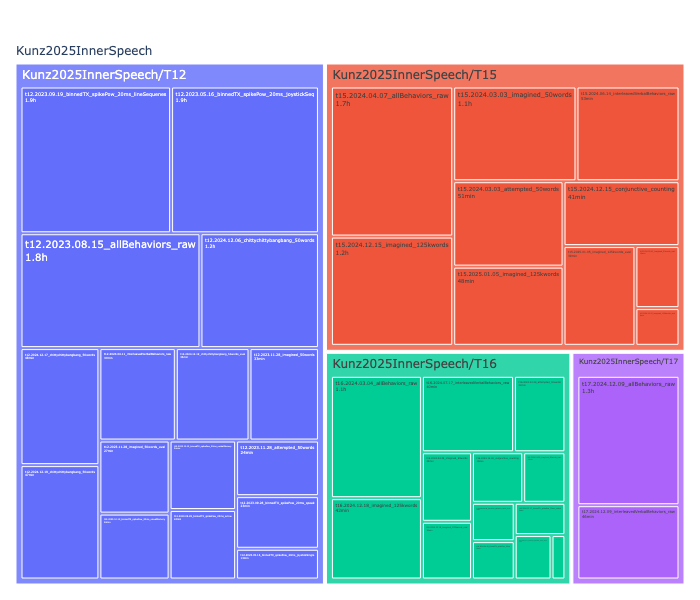

In [7]:
viz.plot_study(readable(kunz, kunz.session))

Now every tile is named and carries its duration, and the imbalance is legible: T12 holds roughly as much recorded time as T15 and T16 together, and T17 contributes two sessions.

The top level of the treemap only earns its place once several studies are pooled, which is the shape a collection actually has. Concatenating events frames is all it takes, since `study` is already a column.

In [8]:
willet23 = build(Willett2023Sentences, "willet_2023")
willet21 = build(Willett2021Handwriting, "willet_2021")

pooled = pd.concat([kunz, willet23, willet21], ignore_index=True)

print(f"{len(pooled)} events, {pooled.study.nunique()} studies, "
      f"{pooled.subject.nunique()} subjects, {pooled.timeline.nunique()} timelines")
print(pooled.groupby("study").timeline.nunique().to_string())

51667 events, 3 studies, 6 subjects, 368 timelines
study
Kunz2025InnerSpeech        41
Willett2021Handwriting     21
Willett2023Sentences      306


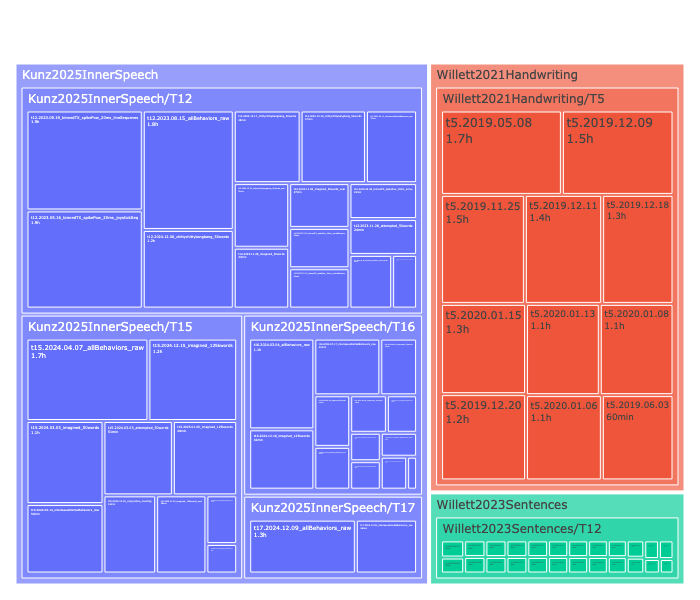

In [9]:
viz.plot_study(readable(pooled, pooled.session))

This is the closest thing in `viz.py` to a collection-level view. Three studies, six subject boxes, and one immediately useful fact: T12 appears twice, once under willet_2023 and once under kunz_2025, and those two boxes hold the same person a year and a half apart.

---
## 3. `plot_overlap`: what is shared, and with whom

`plot_overlap` is an UpSet plot. Pick an event type, pick a grouping dimension `x`, and it computes which groups contain each unique element `y`, then shows the intersection patterns. `y` defaults to `text` for text events and `filepath` for data events.

The first question it answers for kunz_2025: do the four subjects read the same sentence prompts.

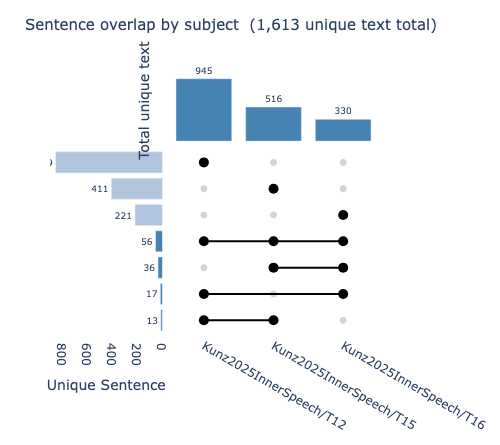

In [10]:
viz.plot_overlap(kunz, event_type="Sentence", x="subject")

Read it top-down: the bars along the top are how many unique sentences each subject saw, the dots below mark which subjects a pattern covers, and the horizontal bars on the left count the sentences in that pattern. So T12 saw 945 unique sentences, 859 of them nobody else saw, and only 56 sentences are common to all three.

That is a small shared core, and it matters directly: a decoder trained across these subjects is mostly not seeing the same language twice.

One thing to watch. Only three subjects appear, but kunz_2025 has four. T17 has no `Sentence` events at all, and a group with no events of the selected type is filtered out rather than drawn as an empty column. Absence and zero look the same here.

In [11]:
print(kunz.groupby("subject").type.value_counts().unstack(fill_value=0).to_string())

type                     BandPower  Sentence  SpikeCounts  Stimulus  Word
subject                                                                  
Kunz2025InnerSpeech/T12         16      1180           16      2791  1596
Kunz2025InnerSpeech/T15         10       720           10       232  1806
Kunz2025InnerSpeech/T16         13       450           13       845  1155
Kunz2025InnerSpeech/T17          2         0            2       159  1512


The same call across studies asks a sharper question, because these three studies were run by overlapping groups and may well have reused prompt sets.

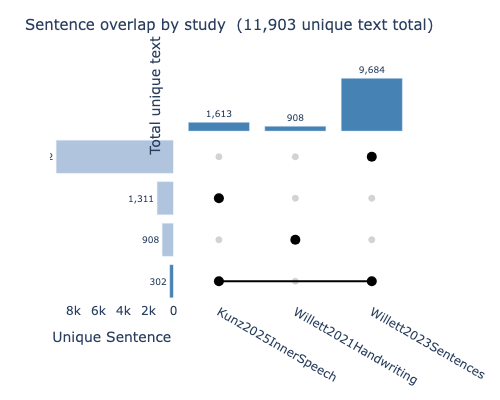

In [12]:
viz.plot_overlap(pooled, event_type="Sentence", x="study")

There it is: **302 sentences appear verbatim in both kunz_2025 and willet_2023**, and willet_2021 shares none with either. Out of 11,903 unique sentences that is small, but it is not nothing, and it is exactly the kind of thing that quietly leaks between a train member and a test member of the same collection.

Worth confirming directly rather than trusting the plot.

In [13]:
sentences = pooled[pooled.type == "Sentence"]
by_study = {s: set(g.text.astype(str)) for s, g in sentences.groupby("study")}

shared = by_study["Kunz2025InnerSpeech"] & by_study["Willett2023Sentences"]
print(f"{len(shared)} sentences shared by kunz_2025 and willet_2023")
for text in sorted(shared)[:5]:
    print("  ", text)

302 sentences shared by kunz_2025 and willet_2023
   A fairly good amount.
   A lot of companies are.
   A really good companion for me.
   About twenty years ago.
   Actually they have.


The function switches representation on its own when the grouping gets wide. Above 20 groups an UpSet dot matrix stops being readable, so it falls back to a sharing-degree histogram plus per-group totals. Grouping the pooled events by session gives 53 groups and triggers it.

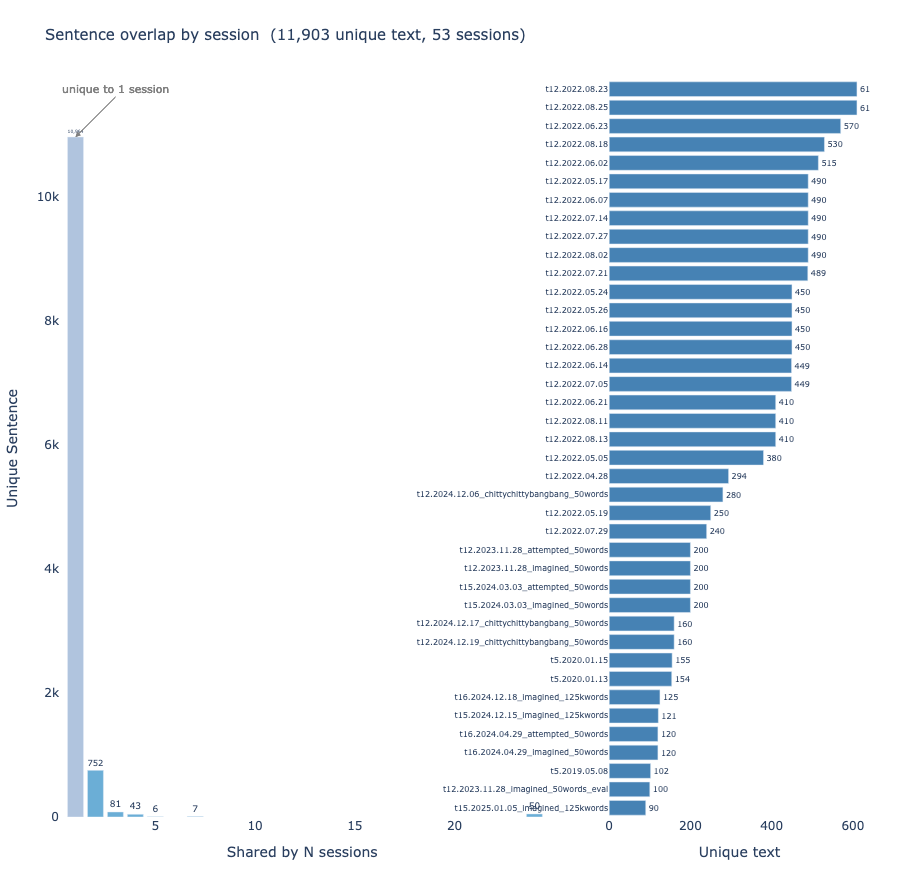

In [14]:
viz.plot_overlap(pooled, event_type="Sentence", x="session")

The corpus is overwhelmingly session-unique: 10,964 sentences appear in exactly one session and 752 in two. The right panel ranks sessions by how much unique language each contributes.

The interesting part is the bar sitting alone at 24. Fifty sentences appear in exactly 24 sessions each, which is not a tail, it is a fixed set being repeated on purpose.

In [15]:
per_text = sentences.groupby(sentences.text.astype(str)).agg(
    n_sessions=("session", "nunique"),
    studies=("study", lambda s: tuple(sorted(set(s)))),
)
repeated = per_text[per_text.n_sessions == 24]

print(f"{len(repeated)} sentences appear in 24 sessions each")
print(repeated.studies.value_counts().to_string())
print()
example = repeated.index[0]
print(f"'{example}' appears in:")
print(sentences[sentences.text.astype(str) == example].groupby("study").session.nunique().to_string())

50 sentences appear in 24 sessions each
studies
(Kunz2025InnerSpeech, Willett2023Sentences)    50

'Are you going outside?' appears in:
study
Kunz2025InnerSpeech      3
Willett2023Sentences    21


Those fifty are willet_2023's fixed evaluation set, repeated on 21 of its sessions. They also make up all three of kunz_2025's `_50words_eval` sessions, one per subject.

So kunz_2025's held-out evaluation prompts are the same fifty sentences willet_2023 repeated all summer. Pool the two studies into one collection and the held-out set of one member is the training set of the other, which no per-dataset split can catch. This is the single most useful thing `plot_overlap` has said so far, and it took one call.

`plot_overlap` is not limited to text. `y` defaults to `filepath` for data events, so the same call over `SpikeCounts` asks whether two groups point at the same source file, which is a duplication check rather than a stimulus-sharing one.

---
## 4. What these three cover

Taken together the three functions cover one altitude well and two altitudes partially.

**Covered.** The single timeline. `plot_events` is genuinely the right first look at any new dataset, and it is the fastest way to see that a Study emits what it claims, in the order it claims.

**Partially covered.** Corpus shape. `plot_study` answers "where is the recorded time" and `plot_overlap` answers "what is shared", but both work off an events frame that somebody had to build first. Neither can read the metadata database, so neither can say anything about the catalogued datasets not yet turned into a Study.

**Not covered.** Everything between one timeline and the whole pile:

- the per-timeline attributes that queries are written against (`task`, `original_split`, `post_implant_day`), which is `study_summary()` and has no plot at all
- which streams each timeline actually emits, currently `pd.crosstab(events.timeline, events.type)`
- anything trial-aligned, which is where a misaligned Study is caught
- the manifest, its layout keys and its conflicts
- the signals themselves

**One fix worth pushing upstream.** Every display problem in this notebook is the same problem. `viz.py` uses `timeline` as a human label and `filepath` as a filename, and in this project both are machine identifiers. A `label=` argument on `plot_events` and `plot_study`, plus skipping the filepath label when it does not parse as a path, would remove the need for `readable` entirely. The title would want one more touch: it joins `study` and `subject`, and since `subject` already carries the study as a prefix, the study name appears twice.